# RQ3 Analysis: Reading Ease

Compares the reading ease (Flesch Kincaid Grade Level) of human-written vs. LLM-generated PR descriptions.

- Uses `textstat.flesch_kincaid_grade` to compute the score.
- Compares across models and prompt context variations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import textstat
from scipy.stats import mannwhitneyu, kruskal
import paired_stats as PS  # Tier-A shared helpers: paired Wilcoxon, FDR, effect sizes
import scikit_posthocs as sp

# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [2]:
csv_path = '/mnt/ext-hdd1/ayo/llm-in-prs/phase3/datasets/temperature_1/run_3_corrected_detection_v1/corpus.csv'
df = pd.read_csv(csv_path)

variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: ['Qwen/Qwen2.5-72B-Instruct' 'gpt-5-mini-2025-08-07'
 'meta-llama/llama-3.1-70b-instruct']
Human entries: 308, AI entries: 5322


## 2. Compute Flesch Kincaid Grade Level

In [3]:
def compute_reading_ease(text):
    """Compute Flesch Kincaid Grade Level for a given text."""
    if pd.isna(text) or str(text).strip() == '':
        return np.nan
    text = str(text)
    return textstat.flesch_kincaid_grade(text)

# Apply to both subsets
human_df['flesch_kincaid_grade'] = human_df['text'].apply(compute_reading_ease)
ai_df['flesch_kincaid_grade'] = ai_df['text'].apply(compute_reading_ease)

# Combine for analysis
combined_df = pd.concat([human_df, ai_df], ignore_index=True)
combined_df['source'] = combined_df['entry_type'].map({'human': 'Human', 'ai': 'AI'})
combined_df = combined_df.dropna(subset=['flesch_kincaid_grade'])

print("Reading ease metrics computed.")
print(f"Combined dataset size: {len(combined_df)}")
display(combined_df[['entry_type', 'model', 'text', 'flesch_kincaid_grade']].head(10))

Reading ease metrics computed.
Combined dataset size: 5630


,entry_type,model,text,flesch_kincaid_grade
0,human,Human,Extracted Regexe in Patterns\r\nFix for #2451\...,10.371806
1,human,Human,Motivation is discussed in #2465. Fixes many c...,7.039643
2,human,Human,…tting down\r\n\r\nFixes #2486. Unregistering ...,7.527500
3,human,Human,Fixes https://github.com/JabRef/jabref/issues/...,13.257353
4,human,Human,"As discussed in #2704, unkown meta data items ...",8.439778
5,human,Human,"As suggested by @koppor in #2671, removes any ...",12.775000
6,human,Human,Followup from @sauliusg PR #2744\r\nFix for ...,2.280000
7,human,Human,See #2789.\r\n> JabRef version 4.0.0-beta on W...,7.981250
8,human,Human,See #2762\r\nAdded a new LayoutFormatter that ...,11.530278
9,human,Human,\r\n![5digitgroups_fixed](https://cloud.github...,10.690909


## 3. Descriptive Statistics: Human vs AI (Overall)

In [4]:
print(f"\n{'='*60}")
print("  Flesch Kincaid Grade Level — Descriptive Statistics")
print(f"{'='*60}")

stats = combined_df.groupby('source')['flesch_kincaid_grade'].describe()
stats['median'] = combined_df.groupby('source')['flesch_kincaid_grade'].median()
display(stats)

for src in ['Human', 'AI']:
    vals = combined_df[combined_df['source'] == src]['flesch_kincaid_grade']
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f"  {src}: Q1={q1:.2f}, Median={vals.median():.2f}, Q3={q3:.2f}, IQR={q3 - q1:.2f}")


  Flesch Kincaid Grade Level — Descriptive Statistics


,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5322.0,13.264007,3.226318,0.72,11.417690,13.066432,14.843445,87.898,13.066432
Human,308.0,11.146668,3.869382,-3.01,9.501806,11.073795,12.939829,44.190,11.073795


  Human: Q1=9.50, Median=11.07, Q3=12.94, IQR=3.44
  AI: Q1=11.42, Median=13.07, Q3=14.84, IQR=3.43


## 4. Descriptive Statistics: By Model

In [5]:
print(f"\n{'='*60}")
print("  Flesch Kincaid Grade Level — By Model")
print(f"{'='*60}")

stats_model = combined_df.groupby('model')['flesch_kincaid_grade'].describe()
stats_model['Median'] = combined_df.groupby('model')['flesch_kincaid_grade'].median()
stats_model['Q1'] = combined_df.groupby('model')['flesch_kincaid_grade'].quantile(0.25)
stats_model['Q3'] = combined_df.groupby('model')['flesch_kincaid_grade'].quantile(0.75)
stats_model['IQR'] = stats_model['Q3'] - stats_model['Q1']

display(stats_model[['count', 'mean', 'std', 'Median', 'Q1', 'Q3', 'IQR']].rename(columns={'count': 'Count', 'mean': 'Mean', 'std': 'Std'}))


  Flesch Kincaid Grade Level — By Model


,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,308.0,11.146668,3.869382,11.073795,9.501806,12.939829,3.438022
Qwen/Qwen2.5-72B-Instruct,1772.0,12.915359,2.148282,12.963913,11.516653,14.340752,2.824099
gpt-5-mini-2025-08-07,1772.0,13.354265,3.251040,13.071686,11.617806,14.692922,3.075115
meta-llama/llama-3.1-70b-instruct,1778.0,13.521525,3.979951,13.250076,10.945149,15.908835,4.963686


## 5. Statistical Testing & Effect Size

In [6]:
# Per-model OVERALL comparison (PAIRED, per-PR mean across contexts) -- Tier-A.
# Replaces independent-samples Mann-Whitney U on paired human/AI data. For each model,
# summarise its six-context output per PR as the mean, then pair against the human value
# for the same PR (Wilcoxon signed-rank). Effect sizes: Cliff's delta (dominance) +
# matched-pairs rank-biserial. FDR (BH) applied within each metric. See paired_stats.py.
models = ai_df['model'].unique()
model_results = []
for _col, _label in [('flesch_kincaid_grade', 'Flesch Kincaid Grade')]:
    _ai_all = ai_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
    _hu_all = human_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
    _m = pd.concat([_hu_all.rename('h'), _ai_all.rename('a')], axis=1, join='inner').dropna()
    _r = PS.paired_test(_m['h'].values, _m['a'].values)
    print("[%s] pooled Human vs AI (paired): n=%d, Wilcoxon p=%.3g, Cliff's d=%.4f (%s)"
          % (_label, _r['n'], _r['p'], _r['cliffs_delta'], _r['magnitude']))
    for _model in ai_df['model'].unique():
        _ai_pr = ai_df[ai_df['model'] == _model].dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
        _hu_pr = human_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
        _merged = pd.concat([_hu_pr.rename('h'), _ai_pr.rename('a')], axis=1, join='inner').dropna()
        _r = PS.paired_test(_merged['h'].values, _merged['a'].values)
        model_results.append({
            'Model': _model, 'Metric': _label, 'N pairs': _r['n'],
            'Human Median': _r['median_human'], 'Model Median': _r['median_ai'],
            'Wilcoxon p': _r['p'], "Cliff's Delta": round(_r['cliffs_delta'], 4),
            'Rank-Biserial': round(_r['rank_biserial'], 4), 'Effect Size': _r['magnitude'],
        })
model_results_df = pd.DataFrame(model_results)
model_results_df = PS.apply_fdr_by(model_results_df, 'Metric', pcol='Wilcoxon p')
model_results_df['Sig'] = model_results_df['adj_Wilcoxon p'].apply(PS.sig_mark)
display(model_results_df)


[Flesch Kincaid Grade] pooled Human vs AI (paired): n=308, Wilcoxon p=1.57e-26, Cliff's d=-0.5340 (Large)


,Model,Metric,N pairs,Human Median,Model Median,Wilcoxon p,Cliff's Delta,Rank-Biserial,Effect Size,adj_Wilcoxon p,sig,Sig
0,Qwen/Qwen2.5-72B-Instruct,Flesch Kincaid Grade,308,11.073795,12.949493,1.124251e-20,-0.4692,-0.6130,Medium,1.124251e-20,True,***
1,gpt-5-mini-2025-08-07,Flesch Kincaid Grade,308,11.073795,13.212156,5.689540e-27,-0.5343,-0.7070,Large,1.706862e-26,True,***
2,meta-llama/llama-3.1-70b-instruct,Flesch Kincaid Grade,308,11.073795,13.433346,1.259488e-26,-0.5322,-0.7021,Large,1.889232e-26,True,***


## 6. Visualizations

/tmp/ipykernel_3069669/3490072165.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_df, x='flesch_kincaid_grade', y='source', palette='Set2')


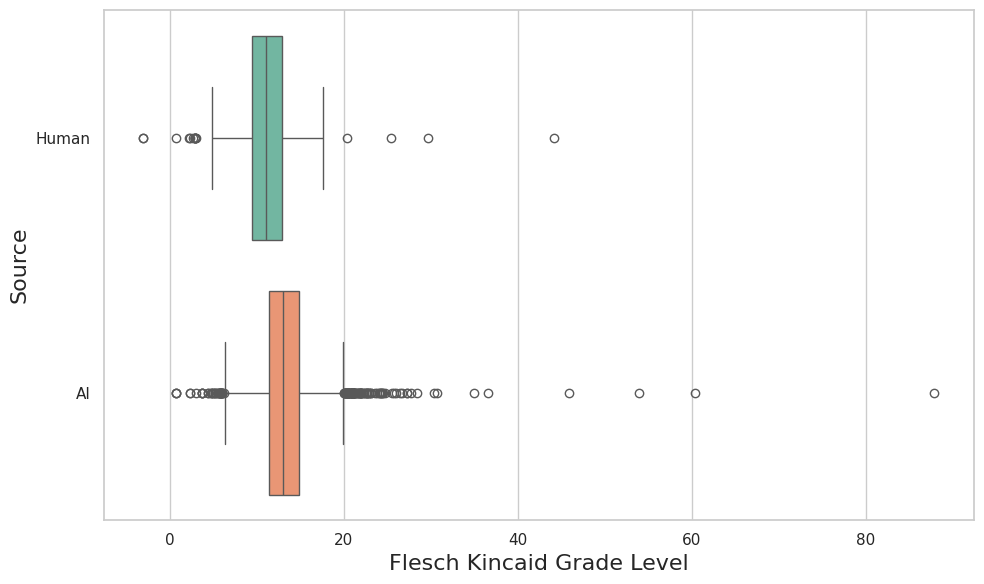

/tmp/ipykernel_3069669/3490072165.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_df, x='flesch_kincaid_grade', y='model', order=order, palette='Set2')


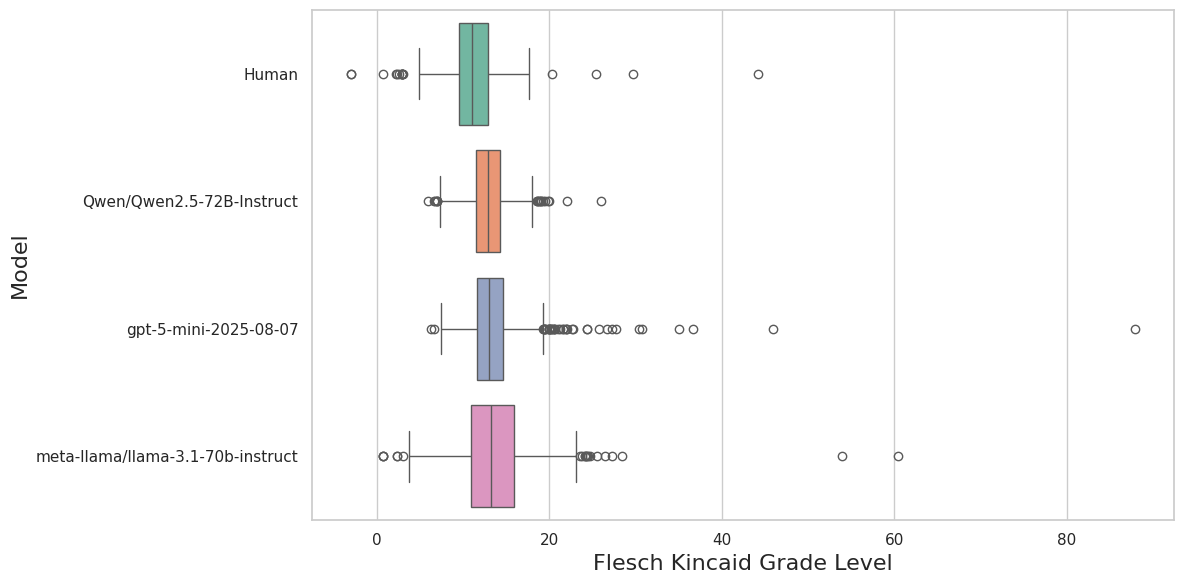

In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined_df, x='flesch_kincaid_grade', y='source', palette='Set2')
plt.xlabel("Flesch Kincaid Grade Level", fontsize=16)
plt.ylabel("Source", fontsize=16)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
order = ['Human'] + list(models)
sns.boxplot(data=combined_df, x='flesch_kincaid_grade', y='model', order=order, palette='Set2')
plt.xlabel("Flesch Kincaid Grade Level", fontsize=16)
plt.ylabel("Model", fontsize=16)
plt.tight_layout()
plt.show()

## 7. FKGL Boxplots by Context per LLM (with Human Baseline)

This mirrors the word-count and sentence-count setup:

- One panel per LLM model (stacked vertically).
- Each panel includes 6 AI context boxplots.
- A Human baseline FKGL boxplot is included in each panel for direct comparison.


  Flesch Kincaid Grade Level — By Prompt Context Variation


,count,mean,std,min,25%,50%,75%,max,median
Context_Name,,,,,,,,,
File Contents,912.0,14.348693,3.706877,0.720000,12.462878,14.077390,15.601468,60.398451,14.077390
File Diff,924.0,13.075684,2.885439,3.718182,11.115093,12.974595,14.895385,22.722857,12.974595
Linked Issue,819.0,12.584250,2.770175,5.504474,10.731893,12.294828,14.114664,24.490000,12.294828
PR Title,924.0,13.538117,2.940102,3.060000,11.680000,13.272548,14.918526,35.013396,13.272548
Repo Path,924.0,13.530560,3.842282,2.311429,11.742167,13.330572,14.978409,87.898000,13.330572
Without File Contents,819.0,12.338395,2.467676,5.805000,10.721499,12.229100,13.779078,21.940000,12.229100


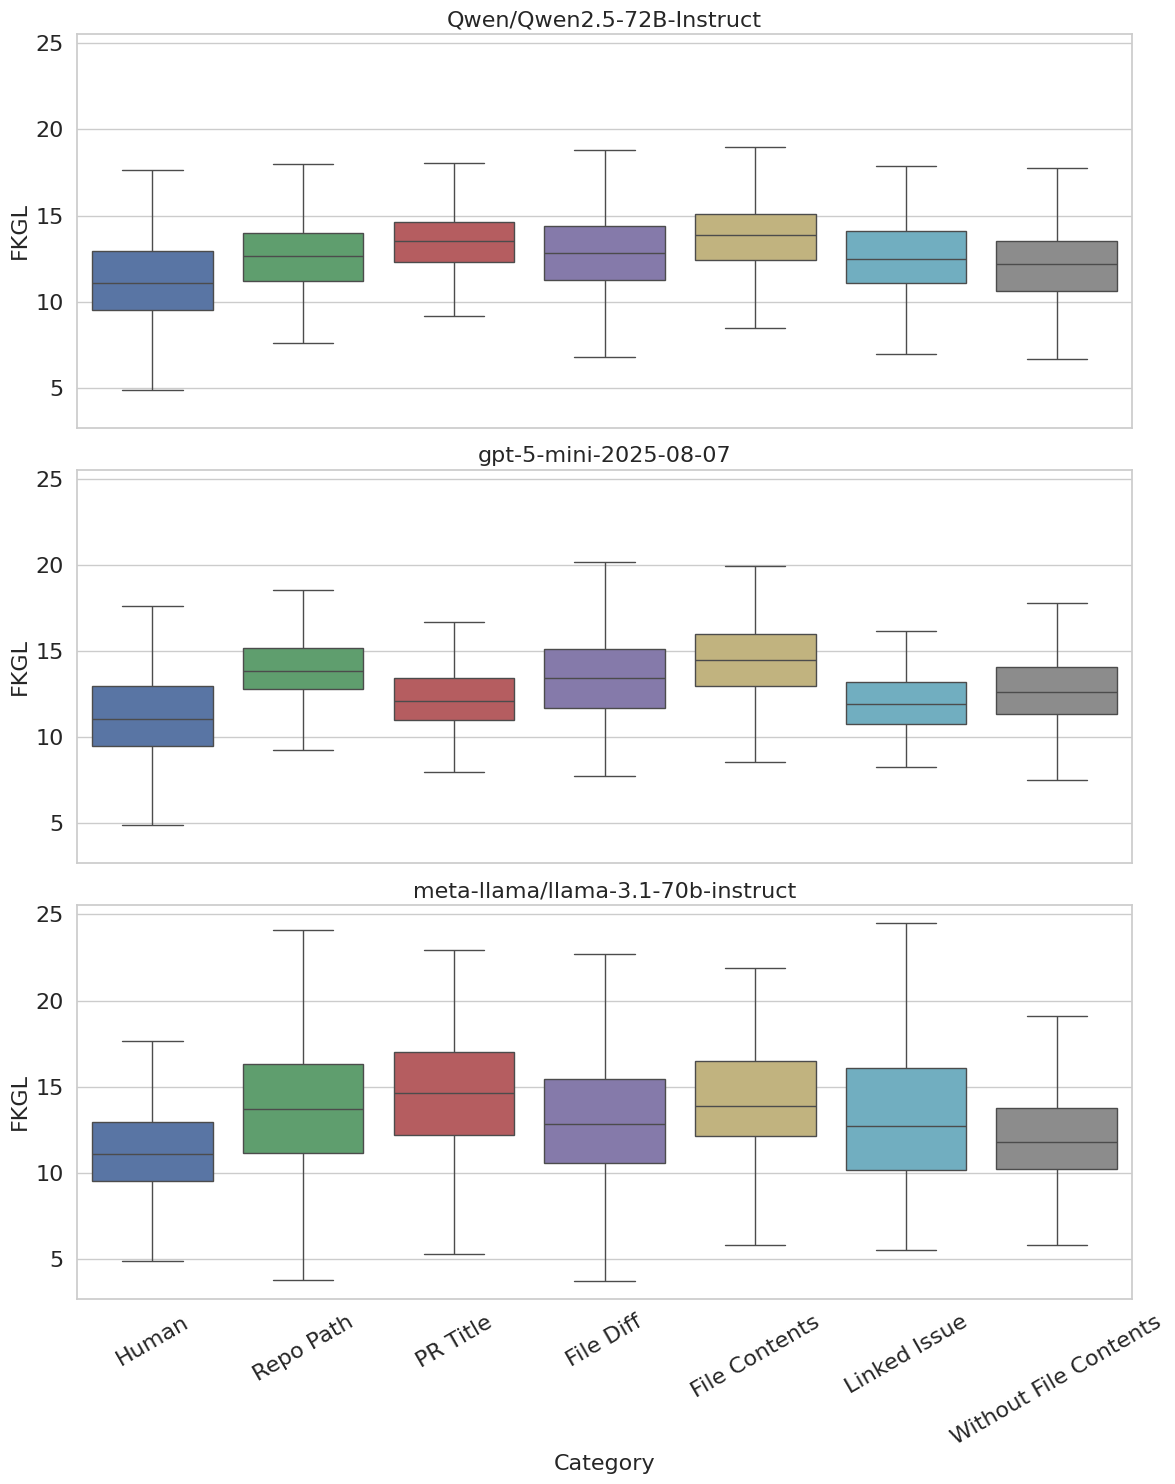

In [8]:
print(f"\n{'='*60}")
print("  Flesch Kincaid Grade Level — By Prompt Context Variation")
print(f"{'='*60}")

# Keep descriptive stats on AI context variation only.
context_df = combined_df[combined_df['source'] == 'AI'].copy()
stats_ctx = context_df.groupby('Context_Name')['flesch_kincaid_grade'].describe()
stats_ctx['median'] = context_df.groupby('Context_Name')['flesch_kincaid_grade'].median()
display(stats_ctx)

context_order = [
    'Repo Path',
    'PR Title',
    'File Diff',
    'File Contents',
    'Linked Issue',
    'Without File Contents'
]

llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=16)

    ai_slice = ai_df[ai_df['model'] == model][['flesch_kincaid_grade', 'Context_Name']].copy()
    ai_slice['Category'] = ai_slice['Context_Name']

    human_slice = human_df[['flesch_kincaid_grade']].copy()
    human_slice['Category'] = 'Human'

    panel_df = pd.concat([
        human_slice[['flesch_kincaid_grade', 'Category']],
        ai_slice[['flesch_kincaid_grade', 'Category']]
    ], ignore_index=True)

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='flesch_kincaid_grade',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=16)
    ax.set_ylabel('FKGL', fontsize=16)
    ax.tick_params(axis='x', rotation=30, labelsize=16)
    ax.tick_params(axis='y', labelsize=16)

plt.tight_layout()
from pathlib import Path
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'fkgl.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 8. Human vs. AI Context Variations (Cliff's δ Effect Sizes per Model)

For each model and each prompt context variation, we compare the paired Human descriptions against the AI-generated descriptions using Cliff's δ effect size measure for Flesch Kincaid Grade Level.

In [9]:
# Human vs. AI per context (PAIRED): Cliff's delta + Wilcoxon signed-rank, BH-FDR -- Tier-A.
# Filter by the stable variation code (P-1..P-6); display labels differ across notebooks
# ('File Diff' vs 'PR Diffs', 'Linked Issue' vs 'Related Issues'), so the code is the safe key.
import os as _os
VARIATION_TO_CTX = {'P-1': 'Repo Path', 'P-2': 'PR Title', 'P-3': 'File Diff', 'P-4': 'File Contents', 'P-5': 'Linked Issue', 'P-6': 'Without File Contents'}
variation_codes = ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
variation_names = [VARIATION_TO_CTX[_p] for _p in variation_codes]
_long = []
for _col, _label in [('flesch_kincaid_grade', 'Flesch Kincaid Grade')]:
    for _model in ai_df['model'].unique():
        for _pcode in variation_codes:
            _slice = ai_df[(ai_df['model'] == _model) & (ai_df['variation'] == _pcode)]
            _r = PS.paired_test_from_frames(human_df, _slice, _col, key='normalized_pr_id')
            _long.append({'Metric': _label, 'Model': _model, 'Context': VARIATION_TO_CTX[_pcode],
                          'n': _r['n'], 'cliffs_delta': _r['cliffs_delta'], 'magnitude': _r['magnitude'],
                          'rank_biserial': _r['rank_biserial'], 'p': _r['p']})
long_df = PS.apply_fdr_by(pd.DataFrame(_long), 'Metric', pcol='p')
long_df['Sig'] = long_df['adj_p'].apply(PS.sig_mark)
_os.makedirs('outputs', exist_ok=True)
long_df.to_csv('outputs/rq2_reading_ease_paired_stats.csv', index=False)
print('Saved tidy paired stats -> outputs/rq2_reading_ease_paired_stats.csv')

def _fmt_cell(x):
    return "%.3f (%s) %s" % (x['cliffs_delta'], x['magnitude'][0], x['Sig'])
context_tables = {}
for _col, _label in [('flesch_kincaid_grade', 'Flesch Kincaid Grade')]:
    _sub = long_df[long_df['Metric'] == _label].copy()
    _sub['cell'] = _sub.apply(_fmt_cell, axis=1)
    _piv = _sub.pivot(index='Model', columns='Context', values='cell').reindex(columns=variation_names)
    context_tables[_label] = _piv
    print("\n=== %s: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===" % _label)
    display(_piv)
result_df = list(context_tables.values())[-1]
effect_df = list(context_tables.values())[-1]


Saved tidy paired stats -> outputs/rq2_reading_ease_paired_stats.csv

=== Flesch Kincaid Grade: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===


Context,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
Qwen/Qwen2.5-72B-Instruct,-0.344 (M) ***,-0.533 (L) ***,-0.361 (M) ***,-0.577 (L) ***,-0.321 (S) ***,-0.252 (S) ***
gpt-5-mini-2025-08-07,-0.617 (L) ***,-0.277 (S) ***,-0.465 (M) ***,-0.664 (L) ***,-0.240 (S) ***,-0.375 (M) ***
meta-llama/llama-3.1-70b-instruct,-0.405 (M) ***,-0.565 (L) ***,-0.304 (S) ***,-0.523 (L) ***,-0.304 (S) ***,-0.174 (S) ***


## 9. Summary Table

In [10]:
summary_rows = []

for model in combined_df['model'].unique():
    vals = combined_df[combined_df['model'] == model]['flesch_kincaid_grade']
    summary_rows.append({
        'Model': model,
        'Metric': 'Flesch Kincaid Grade Level',
        'N': len(vals),
        'Mean': round(vals.mean(), 2),
        'Median': round(vals.median(), 2),
        'Std': round(vals.std(), 2),
        'Min': round(vals.min(), 2),
        'Max': round(vals.max(), 2),
        'Q1': round(vals.quantile(0.25), 2),
        'Q3': round(vals.quantile(0.75), 2)
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

import os
os.makedirs('outputs', exist_ok=True)

# Save summary to CSV
summary_df.to_csv('outputs/rq3_reading_ease_summary.csv', index=False)
print("\nSummary saved to outputs/rq3_reading_ease_summary.csv")

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,Flesch Kincaid Grade Level,308,11.15,11.07,3.87,-3.01,44.19,9.50,12.94
1,Qwen/Qwen2.5-72B-Instruct,Flesch Kincaid Grade Level,1772,12.92,12.96,2.15,5.92,26.05,11.52,14.34
2,gpt-5-mini-2025-08-07,Flesch Kincaid Grade Level,1772,13.35,13.07,3.25,6.34,87.90,11.62,14.69
3,meta-llama/llama-3.1-70b-instruct,Flesch Kincaid Grade Level,1778,13.52,13.25,3.98,0.72,60.40,10.95,15.91



Summary saved to outputs/rq3_reading_ease_summary.csv


In [11]:
from pathlib import Path as _ExportPath
_export_dir = _ExportPath('outputs/row_level')
_export_dir.mkdir(parents=True, exist_ok=True)
_export = pd.concat([human_df, ai_df], ignore_index=True)[
    ['normalized_pr_id', 'entry_type', 'model', 'variation', 'Context_Name', 'flesch_kincaid_grade']
].sort_values(['entry_type', 'model', 'variation', 'normalized_pr_id'], kind='stable')
_export.to_csv(_export_dir / 'fkgl_metrics.csv', index=False)
print(f'Saved {len(_export)} row-level FKGL records.')


Saved 5630 row-level FKGL records.
